Authors:

Myles Lewis and Yuchan Jun

Dataset Background:

The 20 Newsgroups data set comprises around 18,846 articles and discussions, sourced from 20 newsgroups. Topics covered are as diverse as sport, politics, science, religion, computing, cars and medical issues. Each article can be assigned to one of the 20 topic groups and the intention of this project is to determine which group an article should be classed within through analysis of its contents.

In [19]:
# Step 1: Import libraries
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
# Step 2: Load the dataset
# The dataset contains news articles from 20 different
# categories, such as sports, science, politics, and computers.


train_data = fetch_20newsgroups(subset="train")
test_data = fetch_20newsgroups(subset="test")

X_train_text = train_data.data
y_train = train_data.target

X_test_text = test_data.data
y_test = test_data.target

print("Number of training articles:", len(X_train_text))
print("Number of testing articles:", len(X_test_text))
print("Number of categories:", len(train_data.target_names))

Number of training articles: 11314
Number of testing articles: 7532
Number of categories: 20


In [21]:
# Step 3: Convert text into numbers
# TfidfVectorizer looks at important words in each article.

vectorizer = TfidfVectorizer(stop_words="english", max_features=10000)

X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


Training data shape: (11314, 10000)
Testing data shape: (7532, 10000)


In [22]:
# Step 4: Train the Naive Bayes model
# MultinomialNB is used for text data.

model = MultinomialNB()
model.fit(X_train, y_train)

MultinomialNB()

In [23]:
# Step 5: Make predictions

y_pred = model.predict(X_test)

In [24]:
# Step 6: Evaluate the model

accuracy = accuracy_score(y_test, y_pred)
print("Naive Bayes Accuracy:", accuracy)

print(classification_report(y_test, y_pred, target_names=test_data.target_names))

Naive Bayes Accuracy: 0.8081518852894317
                          precision    recall  f1-score   support

             alt.atheism       0.78      0.69      0.73       319
           comp.graphics       0.66      0.75      0.70       389
 comp.os.ms-windows.misc       0.74      0.73      0.74       394
comp.sys.ibm.pc.hardware       0.64      0.73      0.68       392
   comp.sys.mac.hardware       0.84      0.78      0.81       385
          comp.windows.x       0.84      0.76      0.80       395
            misc.forsale       0.82      0.84      0.83       390
               rec.autos       0.86      0.89      0.87       396
         rec.motorcycles       0.90      0.93      0.91       398
      rec.sport.baseball       0.89      0.91      0.90       397
        rec.sport.hockey       0.89      0.97      0.93       399
               sci.crypt       0.89      0.92      0.91       396
         sci.electronics       0.79      0.65      0.71       393
                 sci.med       0.9

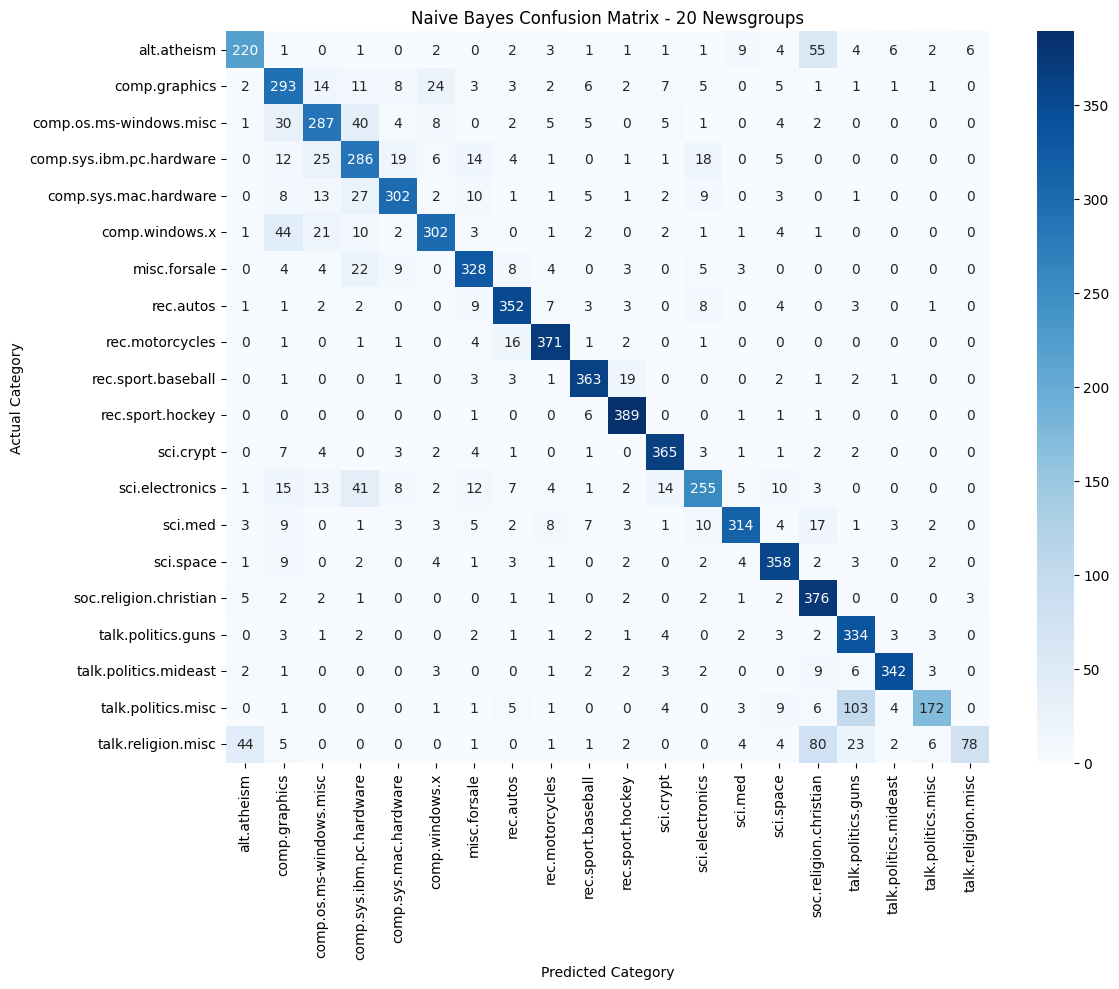

In [25]:
# Step 7: Show the confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=test_data.target_names,   # changed: category names on x-axis
            yticklabels=test_data.target_names)   # changed: category names on y-axis
plt.xticks(rotation=90)                           # new: rotate names so they don't overlap
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Naive Bayes Confusion Matrix - 20 Newsgroups")
plt.tight_layout()                                # new: keeps the long labels from being cut off
plt.show()

In [26]:
# Step 8: Predict brand-new articles the model has never seen
new_articles = [
    "The goalie made 40 saves and the team won in overtime",
    "NASA launched a new satellite to study the orbit of Mars",
    "My graphics card drivers keep crashing when I render 3D images",
    "The doctor prescribed antibiotics for the infection",
]
X_new = vectorizer.transform(new_articles)
preds = model.predict(X_new)
probs = model.predict_proba(X_new)

for text, pred, prob in zip(new_articles, preds, probs):
    print(f"Article: '{text}'")
    print(f"  --> Predicted category: {train_data.target_names[pred]}")
    print(f"  --> Confidence: {prob.max():.1%}\n")

Article: 'The goalie made 40 saves and the team won in overtime'
  --> Predicted category: rec.sport.hockey
  --> Confidence: 49.1%

Article: 'NASA launched a new satellite to study the orbit of Mars'
  --> Predicted category: sci.space
  --> Confidence: 78.2%

Article: 'My graphics card drivers keep crashing when I render 3D images'
  --> Predicted category: comp.graphics
  --> Confidence: 66.8%

Article: 'The doctor prescribed antibiotics for the infection'
  --> Predicted category: sci.med
  --> Confidence: 52.0%



# Conclusion:

A Naive Bayes classifier was used to classify articles from the 20 Newsgroups database. TF-IDF (Term Frequency–Inverse Document Frequency) was applied to emphasise particular words in each article. A Multinomial Naive Bayes classifier was then generated from the training articles. In a test using 7,532 new articles, the classifier achieved a good level of accuracy (81%) and therefore around 6,087 articles were correctly classified. Precision, recall and F1 were all around 0.80. This shows that overall the classifier performed effectively at classifying articles. However, it had the greatest difficulty with ‘talk.religion.misc’ (recall = 31%) and ‘talk.politics.misc’ (recall = 55%), frequently misclassifying these as related topics including ‘soc.religion.christian’, ‘alt.atheism’ and ‘talk.politics.guns’. The classifier successfully identified four completely new articles. These were hockey (confidence = 49.1%), space (78.2%), computer graphics (66.8%) and medicine (52.0%). Reduced confidence was observed for the more brief and generic sentences, as there were fewer unique words for the classifier to base its identification upon. Even so, these confidence levels are high, as with 20 possible categories a random guess would be correct only 5% of the time. Thus it appears that Naive Bayes can be successfully used for classifying textual information.

